# A single qubit with Qiskit

We prepare the one-qubit state $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, draw its circuit, print its statevector, and plot it on the Bloch sphere. The amplitudes must satisfy $|\alpha|^2 + |\beta|^2 = 1$.

The outputs below are saved from a completed run. To change the amplitudes, open this notebook in Jupyter, edit `alpha` and `beta`, and run the cells from top to bottom. This example uses an exact statevector calculation, so no quantum hardware account is needed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

**Create a circuit with one qubit.** Change the two amplitudes below to try your own normalized state. Qiskit orders the amplitudes as $[\alpha,\beta]$, corresponding to $[|0\rangle,|1\rangle]$. The `initialize` instruction prepares those amplitudes on qubit 0.

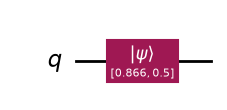

In [2]:
alpha = np.sqrt(3) / 2
beta = 0.5  # Try 0.5j for a complex amplitude with the same magnitude.

amplitudes = np.array([alpha, beta], dtype=complex)
if not np.isclose(np.sum(np.abs(amplitudes) ** 2), 1.0, rtol=0, atol=1e-10):
    raise ValueError("Choose alpha and beta so |alpha|² + |beta|² = 1.")

circuit = QuantumCircuit(1)
circuit.initialize(amplitudes, 0)
figure = circuit.draw(output="mpl")
display(figure)
plt.close(figure)

**Print the quantum state.** `Statevector.from_instruction` evaluates the circuit before any measurement. The array contains complex amplitudes; their squared magnitudes give the measurement probabilities.

In [3]:
state = Statevector.from_instruction(circuit)
np.testing.assert_allclose(state.data, amplitudes, atol=1e-10)

print("Statevector [alpha, beta]:")
print(np.round(state.data, 4))
print(f"|psi> = ({state.data[0]:.4f})|0> + ({state.data[1]:.4f})|1>")
print("Probabilities [P(0), P(1)]:", np.round(state.probabilities(), 4))

Statevector [alpha, beta]:
[0.866+0.j 0.5  +0.j]
|psi> = (0.8660+0.0000j)|0> + (0.5000+0.0000j)|1>
Probabilities [P(0), P(1)]: [0.75 0.25]


**Visualize the state with Qiskit.** The arrow points to the pure state on the Bloch sphere. Its north and south poles represent $|0\rangle$ and $|1\rangle$.

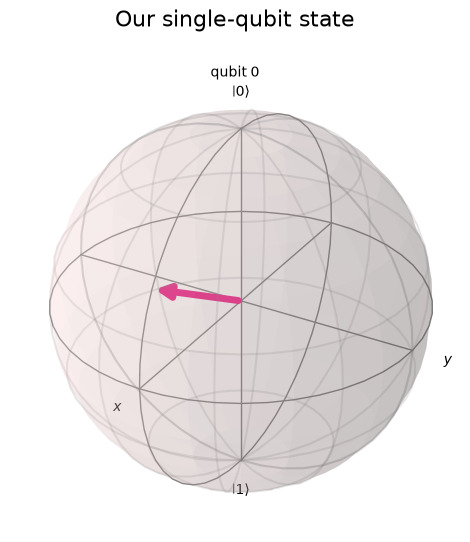

In [4]:
figure = plot_bloch_multivector(state, title="Our single-qubit state")
display(figure)
plt.close(figure)

**Compare different choices of $\alpha$ and $\beta$.** Each example creates a fresh one-qubit circuit, prints its amplitudes and probabilities, and displays its Bloch sphere. In particular, $|+\rangle = (|0\rangle+|1\rangle)/\sqrt{2}$ and $|+i\rangle = (|0\rangle+i|1\rangle)/\sqrt{2}$ have the same measurement probabilities but different relative phases and different Bloch vectors.


|0>: alpha = 1.0000, beta = 0.0000
Statevector: [1.+0.j 0.+0.j]
|psi> = (1.0000+0.0000j)|0> + (0.0000+0.0000j)|1>
P(0), P(1): [1. 0.]


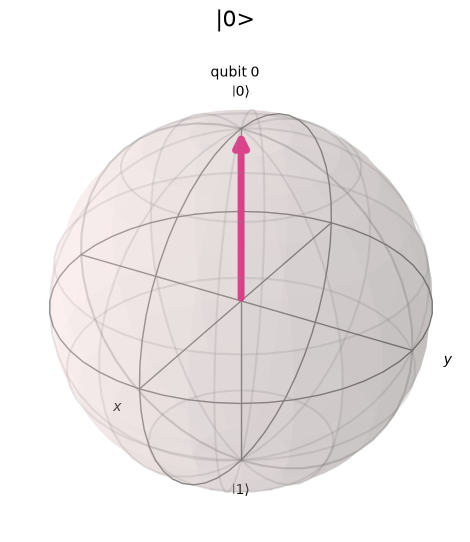


|1>: alpha = 0.0000, beta = 1.0000
Statevector: [0.+0.j 1.+0.j]
|psi> = (0.0000+0.0000j)|0> + (1.0000+0.0000j)|1>
P(0), P(1): [0. 1.]


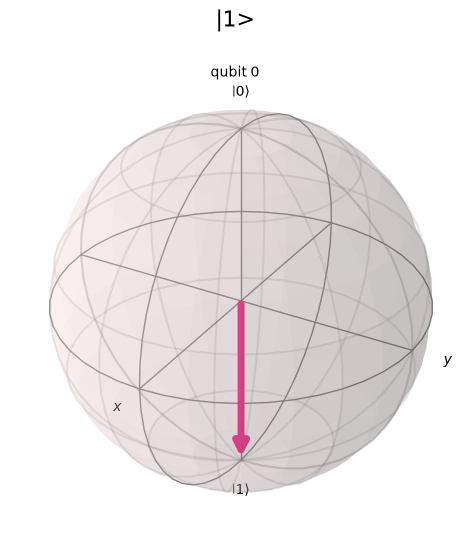


|+>: alpha = 0.7071, beta = 0.7071
Statevector: [0.7071+0.j 0.7071+0.j]
|psi> = (0.7071+0.0000j)|0> + (0.7071+0.0000j)|1>
P(0), P(1): [0.5 0.5]


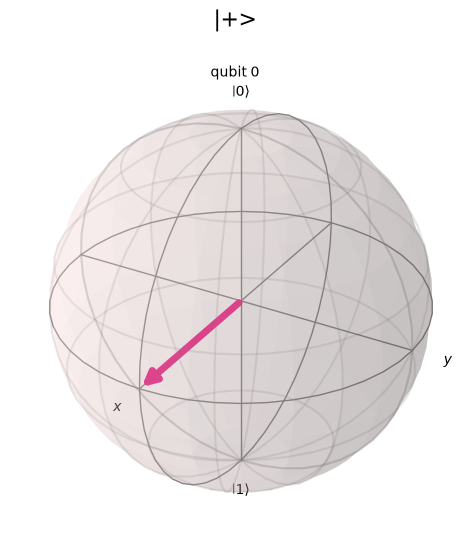


|+i>: alpha = 0.7071, beta = 0.0000+0.7071j
Statevector: [0.7071+0.j     0.    +0.7071j]
|psi> = (0.7071+0.0000j)|0> + (0.0000+0.7071j)|1>
P(0), P(1): [0.5 0.5]


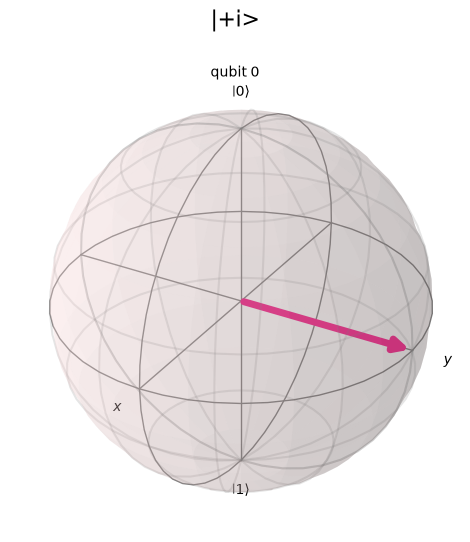

In [5]:
examples = [
    ("|0>", 1, 0),
    ("|1>", 0, 1),
    ("|+>", 1 / np.sqrt(2), 1 / np.sqrt(2)),
    ("|+i>", 1 / np.sqrt(2), 1j / np.sqrt(2)),
]

for name, alpha_example, beta_example in examples:
    example_circuit = QuantumCircuit(1)
    example_circuit.initialize([alpha_example, beta_example], 0)
    example_state = Statevector.from_instruction(example_circuit)
    np.testing.assert_allclose(
        example_state.data, [alpha_example, beta_example], atol=1e-10
    )

    print(f"\n{name}: alpha = {alpha_example:.4f}, beta = {beta_example:.4f}")
    print("Statevector:", np.round(example_state.data, 4))
    print(
        f"|psi> = ({example_state.data[0]:.4f})|0> + ({example_state.data[1]:.4f})|1>"
    )
    print("P(0), P(1):", np.round(example_state.probabilities(), 4))
    figure = plot_bloch_multivector(example_state, title=name)
    display(figure)
    plt.close(figure)

Qiskit reference: [Statevector](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.3/qiskit.quantum_info.Statevector) and [plot_bloch_multivector](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.3/qiskit.visualization.plot_bloch_multivector).